# DSCI 552 - Homework 4

**Name:** Ruturaj Mohalkar  
**GitHub Username:** ruturaj-mohalkar-25  
**USC ID:** 6930537443

## Imports

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, confusion_matrix, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler, StandardScaler, label_binarize

# The assignment notes that (nearly) separable classes make unpenalized logistic regression
# diverge, and suggests capping the iterations. That cap raises a ConvergenceWarning on every
# fit, so the warning is silenced here rather than printed thousands of times.
warnings.filterwarnings('ignore', category=ConvergenceWarning)

RANDOM_STATE = 42

# 1. Time Series Classification Part 1: Feature Creation/Extraction

*This part was the programming assignment of Homework 3 and is not itself submitted for Homework 4. It is included because every model below is built on the features it creates, as the assignment suggests.*

## 1(a) The AReM data set

The data set is stored under `data/AReM/`: seven activity folders, 88 instances in total, each holding 6 time series of 480 values. Four files deviate from the common format. `bending2/dataset4.csv` is space-separated, `cycling/dataset9.csv` and `cycling/dataset14.csv` end their last row with a stray comma, and `sitting/dataset8.csv` has 479 rows instead of 480. Rows are split on any run of commas or whitespace and the first 7 fields are kept. No values are altered.

In [2]:
DATA_DIR = Path('../data/AReM')
SERIES = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']


def read_instance(path):
    """Read one AReM file. Handles comma- or space-separated rows and stray trailing separators."""
    rows = []
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        fields = [f for f in re.split(r'[,\s]+', line) if f]
        rows.append([float(f) for f in fields[:7]])
    return pd.DataFrame(rows, columns=['time'] + SERIES)


instances = []
for activity in sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir()):
    for path in sorted(DATA_DIR.glob(f'{activity}/dataset*.csv'),
                       key=lambda p: int(re.search(r'\d+', p.stem).group())):
        instances.append({
            'activity': activity,
            'dataset': int(re.search(r'\d+', path.stem).group()),
            'data': read_instance(path),
        })

print('Instances:', len(instances))
print('Activities:', sorted({i['activity'] for i in instances}))

Instances: 88
Activities: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']


## 1(b) Train/test split

Datasets 1 and 2 of `bending1` and `bending2`, and datasets 1, 2 and 3 of the other folders, are the test data; the rest is training data.

In [3]:
def is_test(instance):
    """Datasets 1-2 of the bending folders and 1-3 of the others form the test set."""
    limit = 2 if instance['activity'].startswith('bending') else 3
    return instance['dataset'] <= limit


train_instances = [i for i in instances if not is_test(i)]
test_instances = [i for i in instances if is_test(i)]

activity_train = np.array([i['activity'] for i in train_instances])
activity_test = np.array([i['activity'] for i in test_instances])

# Binary problem: bending (1) against every other activity (0)
y_train = (np.char.startswith(activity_train, 'bending')).astype(int)
y_test = (np.char.startswith(activity_test, 'bending')).astype(int)

print('Train instances:', len(train_instances), '| bending:', y_train.sum(), '| other:', (1 - y_train).sum())
print('Test instances: ', len(test_instances), '| bending:', y_test.sum(), '| other:', (1 - y_test).sum())

Train instances: 69 | bending: 9 | other: 60
Test instances:  19 | bending: 4 | other: 15


## 1(c) Feature extraction

The seven time-domain features are the minimum, maximum, mean, median, standard deviation, first quartile and third quartile. When a time series is broken into *l* parts, the same seven features are extracted from each part, giving 7 × 6 × l features per instance. The columns are named `<feature><series>_<part>`, so `mean2_3` is the mean of the third part of the second time series.

Following 1(c)iv of Homework 3, the three features used for the scatter plots are the **minimum, mean and maximum**.

In [4]:
FEATURES = {
    'min': np.min,
    'max': np.max,
    'mean': np.mean,
    'median': np.median,
    'std': lambda x: np.std(x, ddof=1),
    '1st_quart': lambda x: np.quantile(x, 0.25),
    '3rd_quart': lambda x: np.quantile(x, 0.75),
}
SELECTED_FEATURES = ['min', 'mean', 'max']
L_VALUES = range(1, 21)


def instance_features(data, l):
    """Break each of the 6 time series into l approximately equal parts and extract the 7 features from each."""
    row = {}
    for i, s in enumerate(SERIES, start=1):
        for part, chunk in enumerate(np.array_split(data[s].to_numpy(), l), start=1):
            for name, fn in FEATURES.items():
                row[f'{name}{i}_{part}'] = fn(chunk)
    return row


def feature_matrix(subset, l):
    """Feature matrix of a list of instances, for a given number of splits l."""
    return pd.DataFrame([instance_features(i['data'], l) for i in subset])


# Every value of l is needed repeatedly below, so build the matrices once.
X_train_by_l = {l: feature_matrix(train_instances, l) for l in L_VALUES}
X_test_by_l = {l: feature_matrix(test_instances, l) for l in L_VALUES}

print('l = 1  ->', X_train_by_l[1].shape[1], 'features')
print('l = 2  ->', X_train_by_l[2].shape[1], 'features')
print('l = 20 ->', X_train_by_l[20].shape[1], 'features')
X_train_by_l[1].iloc[:5, :7].round(3)

l = 1  -> 42 features
l = 2  -> 84 features
l = 20 -> 840 features


,min1_1,max1_1,mean1_1,median1_1,std1_1,1st_quart1_1,3rd_quart1_1
0,35.00,47.40,43.954,44.33,1.559,43.00,45.00
1,33.00,47.75,42.180,43.50,3.671,39.15,45.00
2,33.00,45.75,41.678,41.75,2.243,41.33,42.75
3,37.00,48.00,43.455,43.25,1.386,42.50,45.00
4,36.25,48.00,43.969,44.50,1.618,43.31,44.67


# 2. Time Series Classification Part 2: Binary and Multiclass Classification

## 2(a) Binary Classification Using Logistic Regression

### 2(a)i. Scatter plots of min, mean and max of time series 1, 2 and 6

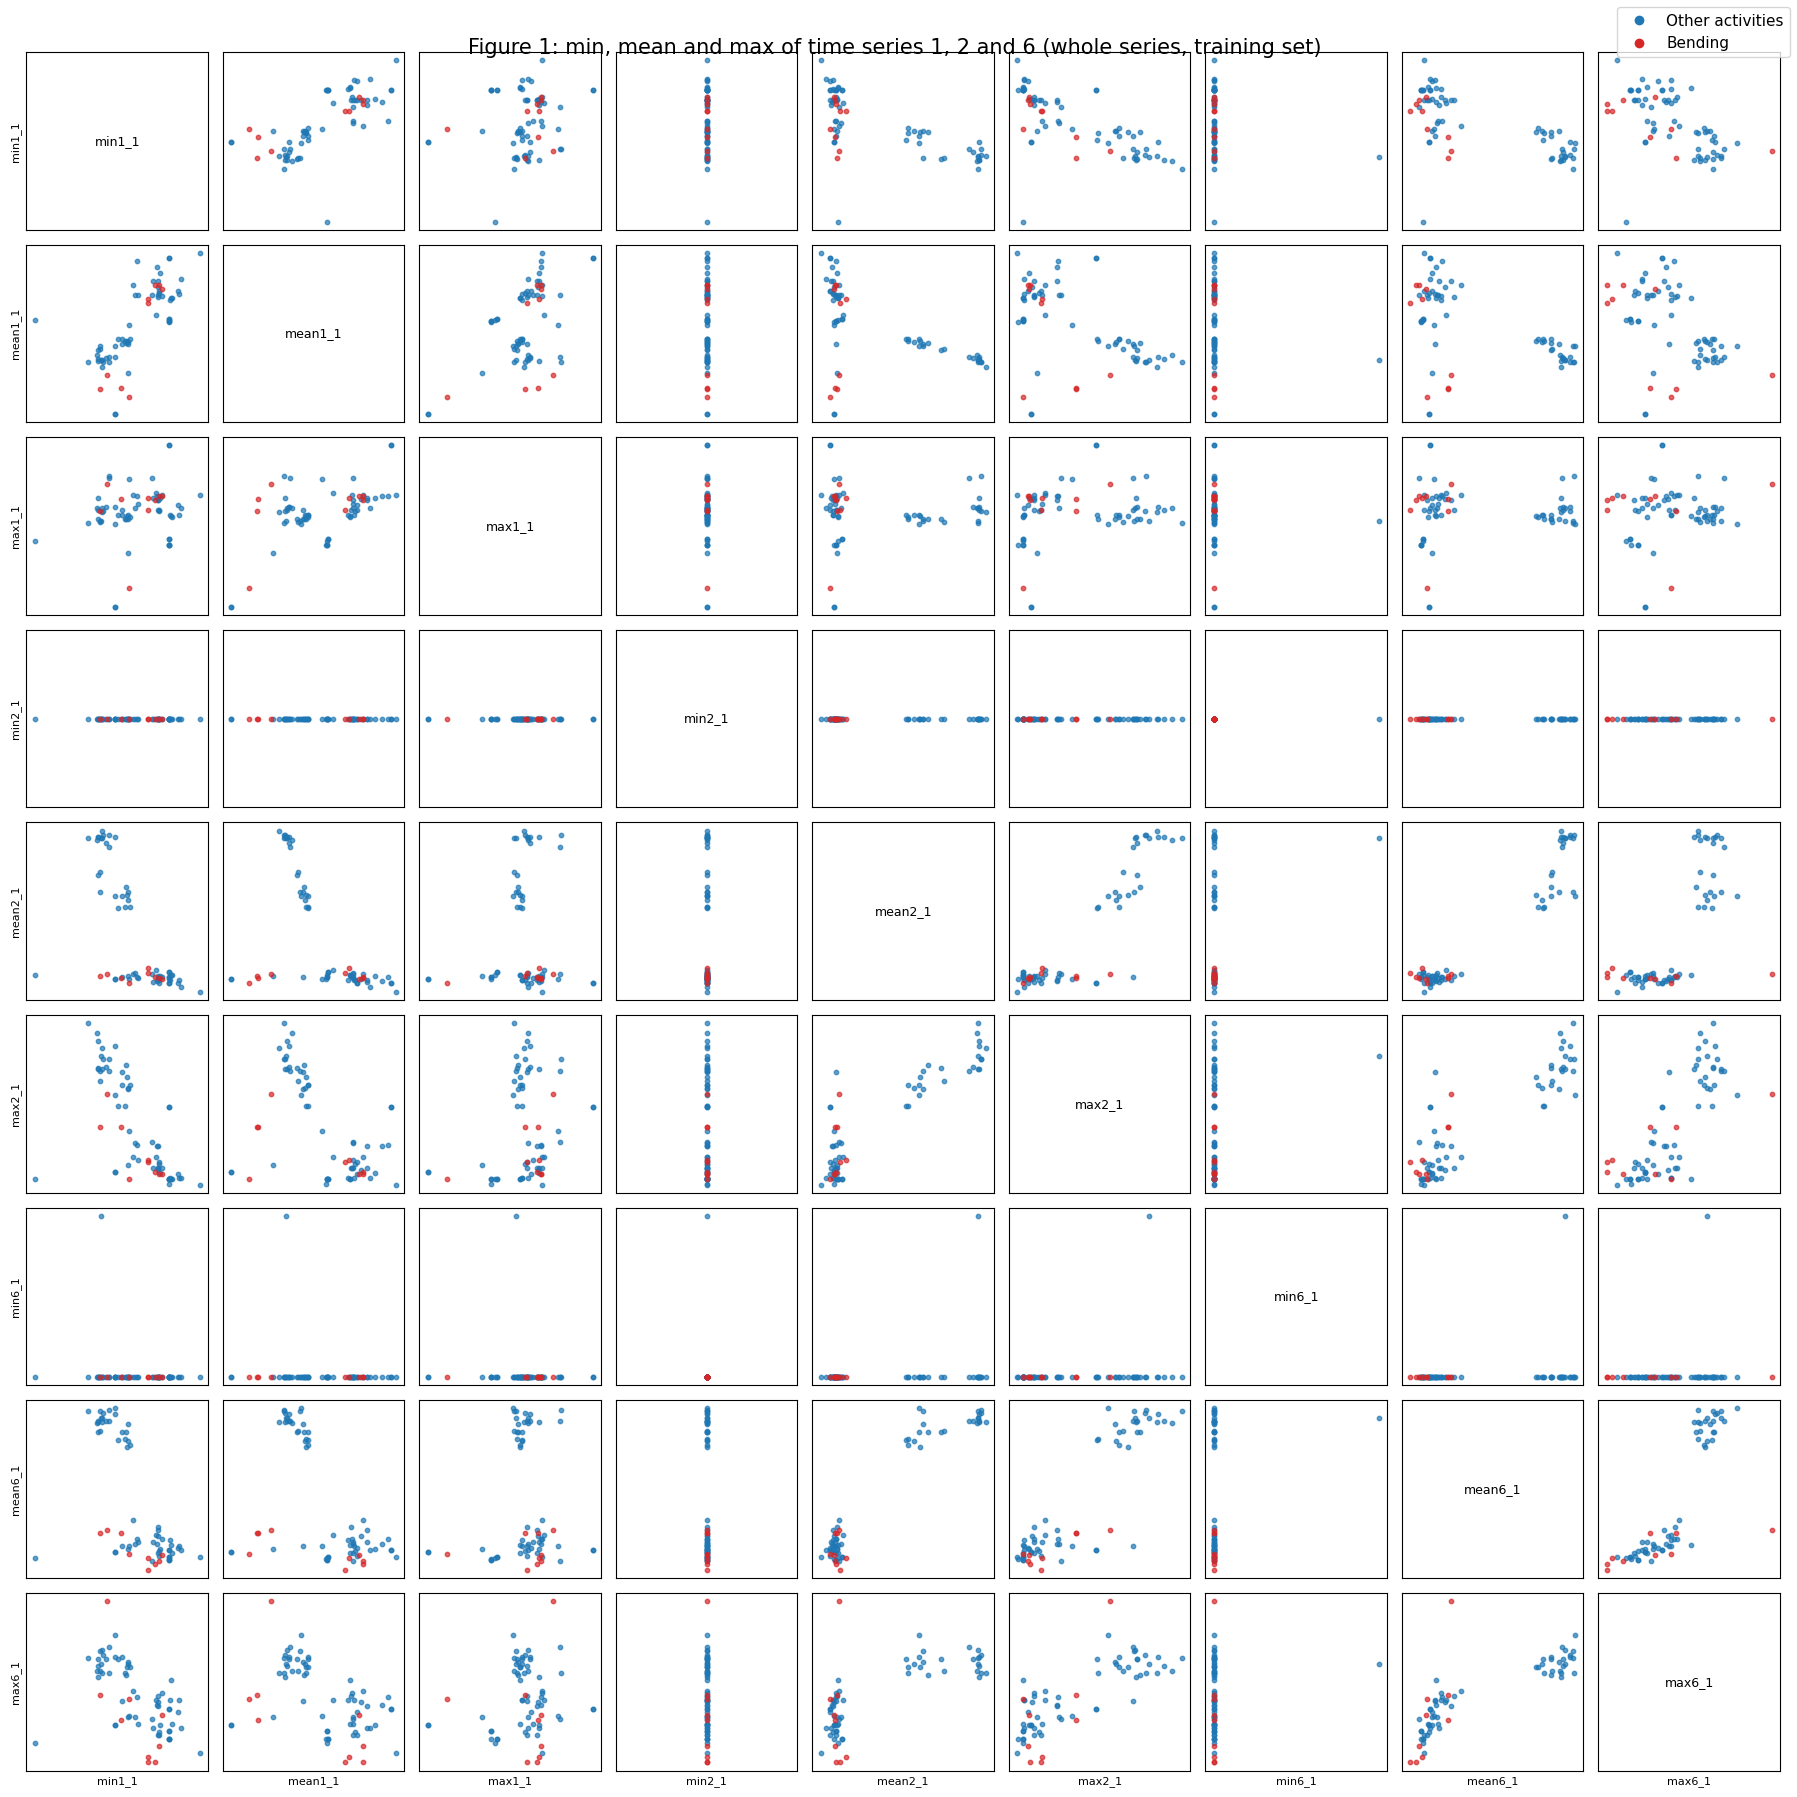

In [5]:
def scatter_matrix_by_class(X, y, title):
    """Pairwise scatter plots of the columns of X, coloured by binary class y."""
    cols = list(X.columns)
    n = len(cols)
    styles = [(0, 'tab:blue', 'Other activities'), (1, 'tab:red', 'Bending')]
    fig, axes = plt.subplots(n, n, figsize=(2.0 * n, 2.0 * n))
    for r in range(n):
        for c in range(n):
            ax = axes[r, c]
            if r == c:
                ax.text(0.5, 0.5, cols[r], ha='center', va='center', fontsize=9)
            else:
                for cls, color, label in styles:
                    mask = y == cls
                    ax.scatter(X.loc[mask, cols[c]], X.loc[mask, cols[r]],
                               s=10, alpha=0.7, color=color, label=label)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == n - 1:
                ax.set_xlabel(cols[c], fontsize=8)
            if c == 0:
                ax.set_ylabel(cols[r], fontsize=8)
    handles = [plt.Line2D([], [], marker='o', ls='', color=color, label=label)
               for _, color, label in styles]
    fig.legend(handles=handles, loc='upper right', fontsize=11)
    fig.suptitle(title, fontsize=15)
    fig.tight_layout()
    plt.show()


plot_cols_1 = [f'{name}{s}_1' for s in (1, 2, 6) for name in SELECTED_FEATURES]
scatter_matrix_by_class(X_train_by_l[1][plot_cols_1], y_train,
                        'Figure 1: min, mean and max of time series 1, 2 and 6 (whole series, training set)')

**Answer 2(a)i:** Bending separates from the other activities remarkably well, even in these raw two-dimensional views. The clearest signal comes from time series 6 (`var_rss23`) and time series 1 (`avg_rss12`): the bending instances sit in a tight, isolated cluster, because bending holds the body in a posture that keeps the sensor readings steady and at a distinctive level, while activities like walking and cycling spread widely. Several individual pairs already look linearly separable on their own, which foreshadows the perfect-separation issue that appears in 2(a)vi. Time series 2 (`var_rss12`) is the least useful of the three, with heavy overlap between the classes.

### 2(a)ii. The same plots after breaking each time series into two halves

With l = 2 each of the 6 time series becomes 2 series, so the training instances now have 12 time series and twice as many features. The features of time series 1, 2 and 6 are shown for each half separately, so that the two halves can be compared with Figure 1 directly.

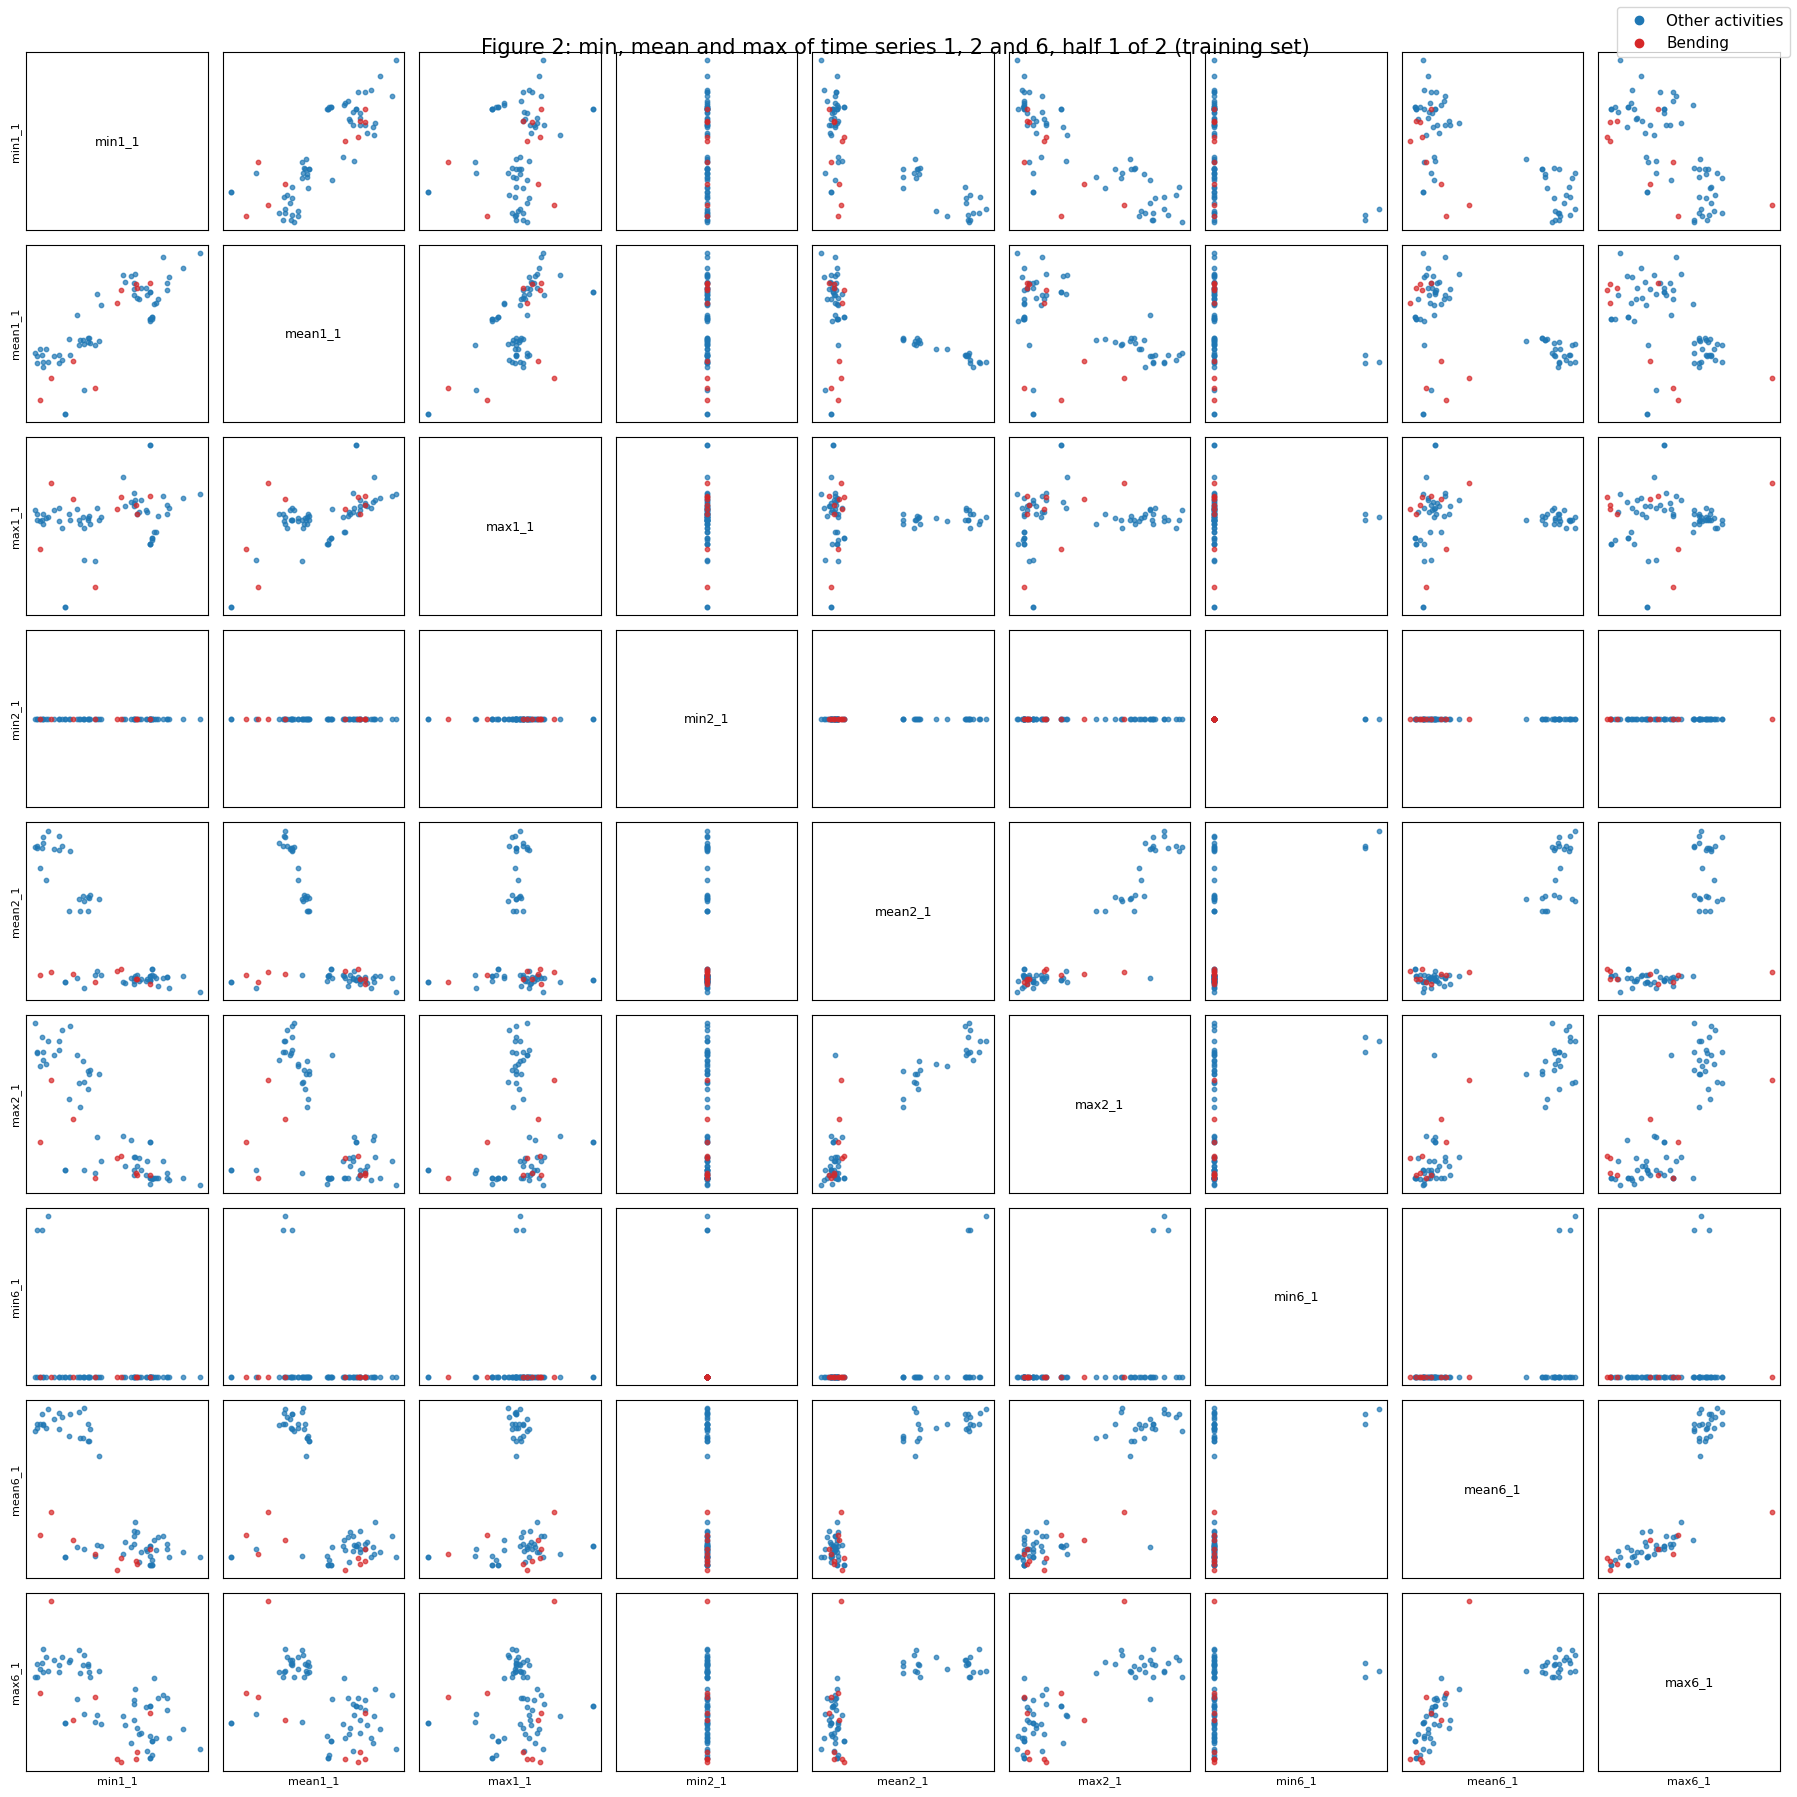

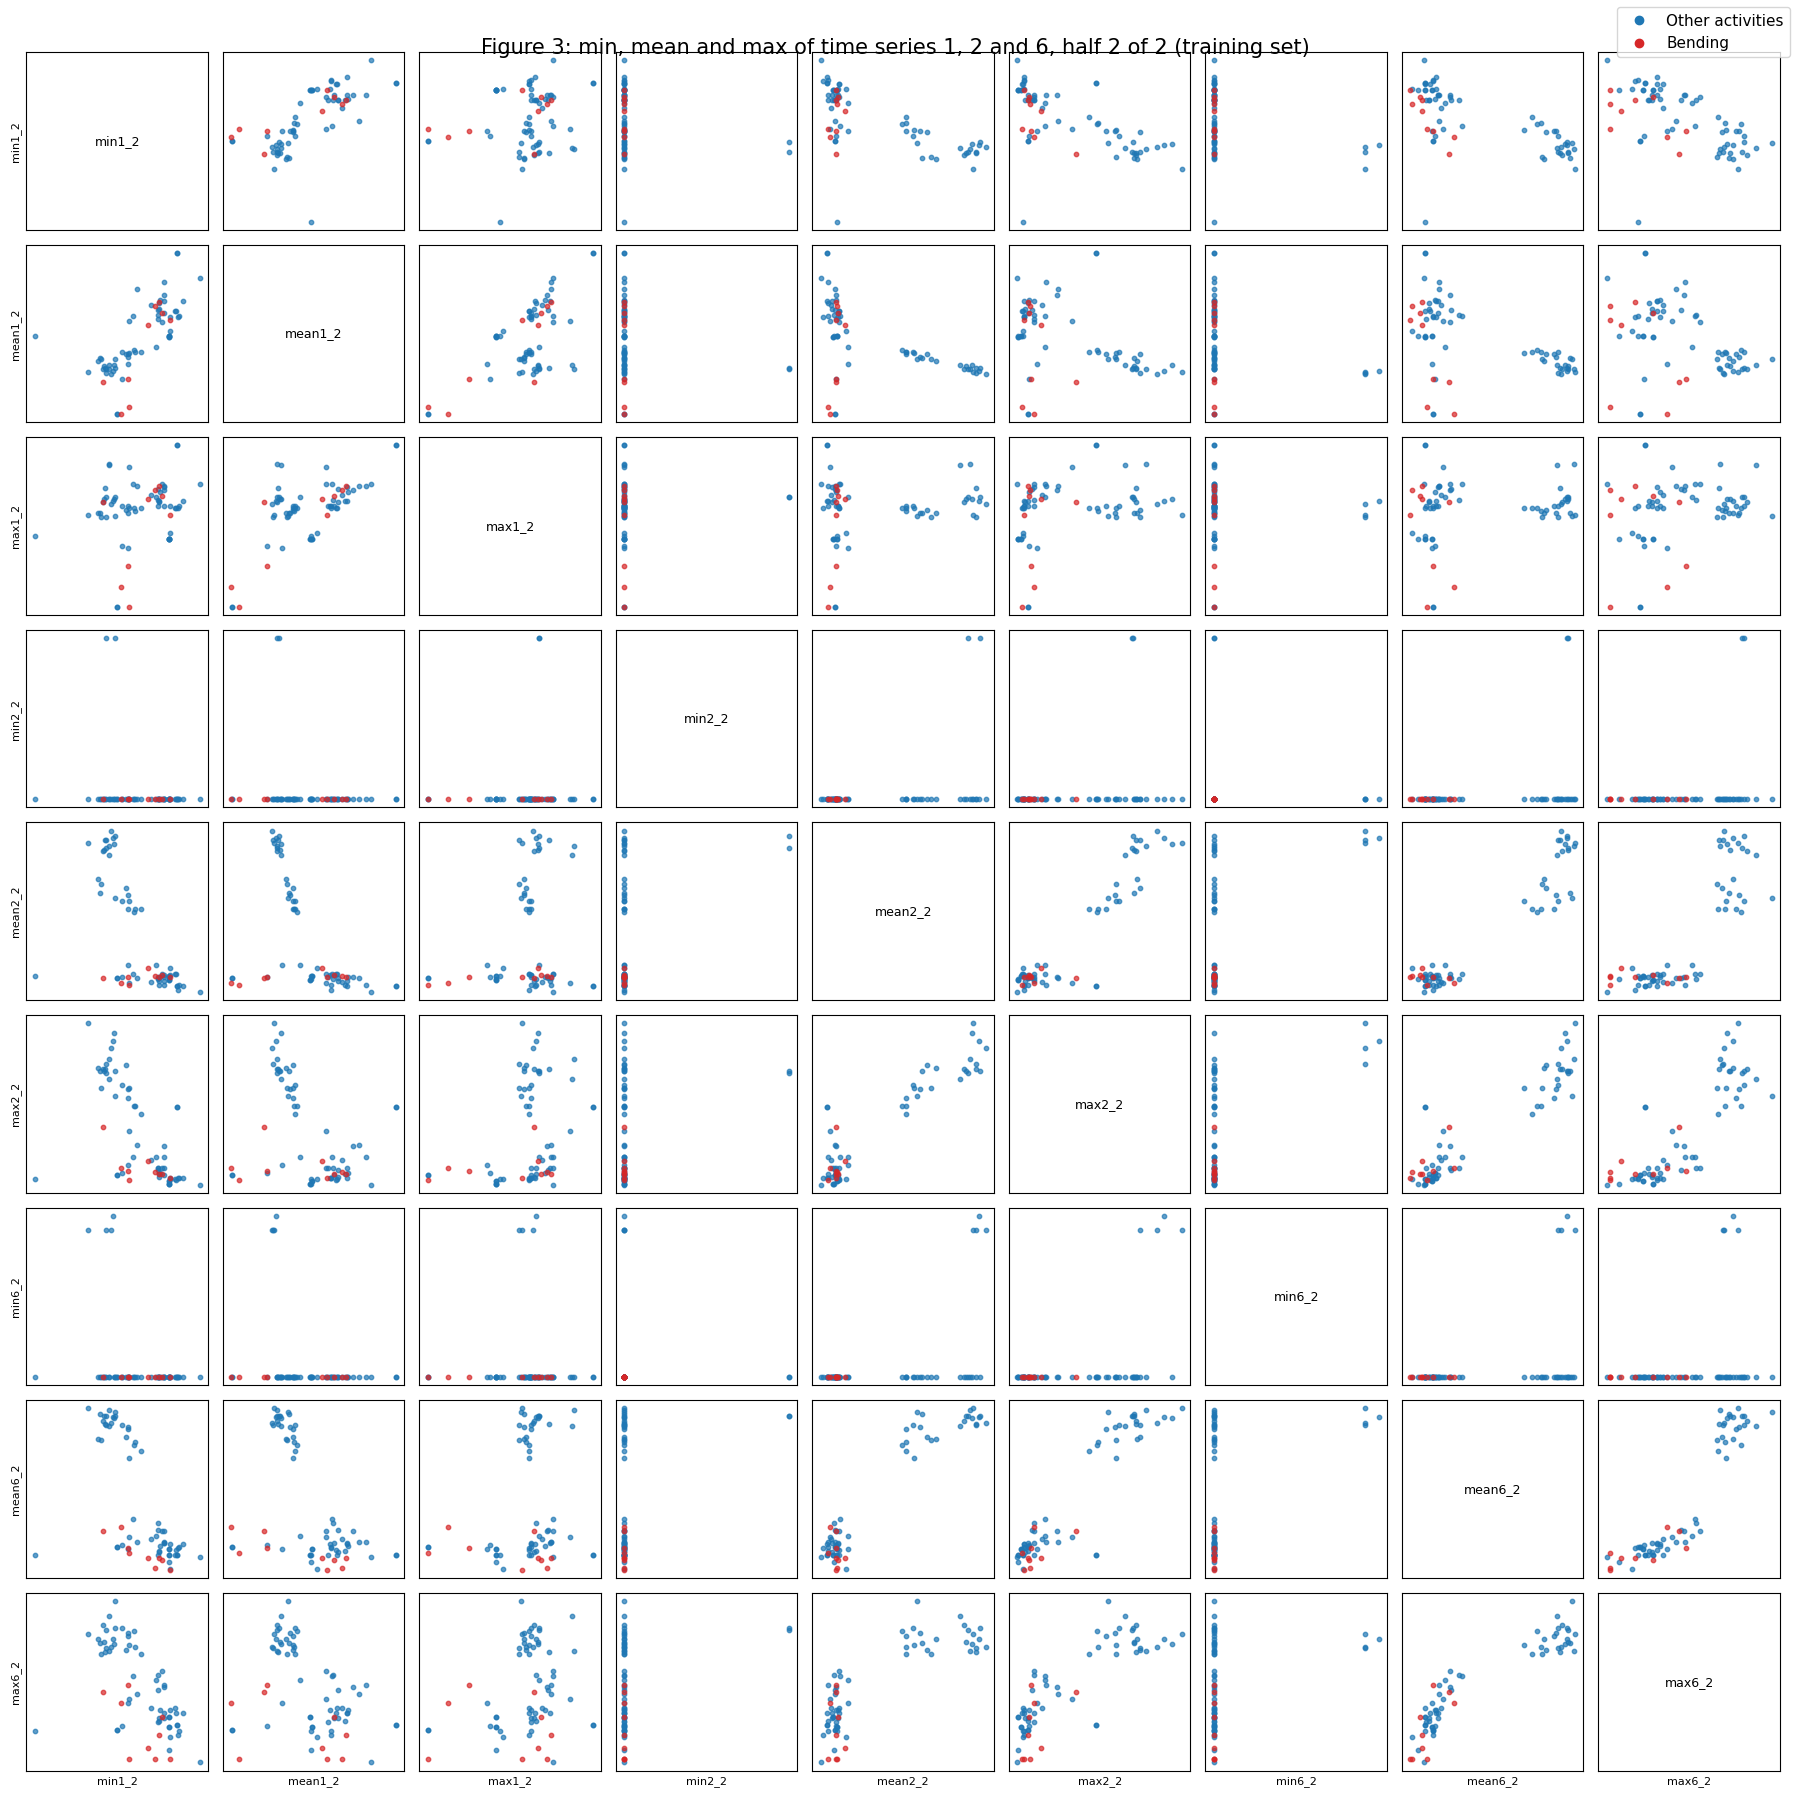

In [6]:
for part in (1, 2):
    cols = [f'{name}{s}_{part}' for s in (1, 2, 6) for name in SELECTED_FEATURES]
    scatter_matrix_by_class(
        X_train_by_l[2][cols], y_train,
        f'Figure {part + 1}: min, mean and max of time series 1, 2 and 6, half {part} of 2 (training set)')

**Answer 2(a)ii:** There is **no considerable difference** in the overall picture. Both halves reproduce the structure of Figure 1: bending forms the same isolated cluster and the same pairs of features separate the classes. This is expected, since these activities are roughly stationary over the two-minute recording, so each half is a fair sample of the whole and its summary statistics are close to those of the full series.

Two smaller differences are visible. First, each cluster is slightly more scattered than in Figure 1, because each feature is now computed from 240 values instead of 480 and is therefore a noisier estimate. Second, the two halves are not identical to each other, since an instance can drift between the first and second minute, and that difference is exactly what makes splitting useful: it doubles the number of features without reducing the number of instances, giving the classifier a chance to exploit changes over time. Whether that helps or simply adds variance is what the cross-validation over l in 2(a)iii decides.

### 2(a)iii. Choosing l and p by 5-fold cross-validation

#### The right and the wrong way to cross-validate here

The number of features depends on l, and the features themselves are then pruned by recursive feature elimination (RFE) down to p of them. Both choices are part of the training procedure, which decides how cross-validation must be run.

**The wrong way** is to run RFE once on the *whole* training set, find the p best features, and only then split into folds to estimate accuracy. The selection has already looked at every observation, including the ones that will serve as validation data, so each fold is scored on features chosen with knowledge of its own labels. This *selection bias* (sometimes called leakage) makes the cross-validation accuracy optimistically biased, sometimes dramatically so when the number of candidate features (up to 840 here) dwarfs the number of instances (69).

**The right way** is to treat feature selection as part of the model. For each candidate pair (l, p) and for each of the 5 folds: build the features from the 4 training folds only, run RFE on those folds only, fit the logistic regression on the selected columns, and only then score the held-out fold. The validation fold takes no part in choosing its own features, so the resulting estimate is honest. That is what the loop below does, and the test set is not touched at all during this search.

**Stratified folds.** Bending is the rare class: the training set has only 9 bending instances against 60 others. Ordinary 5-fold splitting could easily produce a fold with no bending instance at all, which makes the accuracy on that fold meaningless and can make the fit fail. `StratifiedKFold` keeps the class proportions of the full training set in every fold, so each fold contains one or two bending instances.

In [7]:
P_VALUES = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


def logistic():
    """Unpenalized logistic regression.

    C=np.inf removes scikit-learn's built-in L2 penalty (an infinite budget), and max_iter is
    deliberately capped, as footnote 5 of the assignment suggests, so that separable classes
    cannot drive the coefficients off to infinity.
    """
    return LogisticRegression(C=np.inf, solver='lbfgs', max_iter=100)


def cv_accuracy(X, y, p, n_splits=5):
    """5-fold stratified CV accuracy with RFE run inside each fold (the right way)."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    scores = []
    for train_idx, val_idx in skf.split(X, y):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        rfe = RFE(logistic(), n_features_to_select=p, step=0.2).fit(X_tr, y[train_idx])
        model = logistic().fit(rfe.transform(X_tr), y[train_idx])
        scores.append(model.score(rfe.transform(X_val), y[val_idx]))
    return float(np.mean(scores))


cv_results = pd.DataFrame(
    [[cv_accuracy(X_train_by_l[l], y_train, p) for p in P_VALUES] for l in L_VALUES],
    index=pd.Index(L_VALUES, name='l'), columns=pd.Index(P_VALUES, name='p'))

best_l, best_p = cv_results.stack().idxmax()
best_cv_accuracy = cv_results.stack().max()
print(f'Best (l, p) = ({best_l}, {best_p}) with 5-fold CV accuracy {best_cv_accuracy:.4f}')
cv_results.round(3)

Best (l, p) = (1, 7) with 5-fold CV accuracy 1.0000


p,1,2,3,4,5,6,7,8,9,10
l,,,,,,,,,,
1,0.885,0.927,0.971,0.943,0.957,0.957,1.000,0.986,0.986,0.971
2,0.899,0.885,0.885,0.914,0.929,0.913,0.927,0.942,0.957,0.943
3,0.942,0.970,0.956,0.943,0.913,0.942,0.943,0.957,0.971,0.957
4,0.914,0.927,0.927,0.913,0.899,0.899,0.942,0.899,0.913,0.942
5,0.943,0.943,0.927,0.942,0.942,0.986,0.971,0.956,0.956,0.956
6,0.956,0.942,0.942,0.957,0.971,0.942,0.956,0.942,0.956,0.970
7,0.856,0.927,0.942,0.913,0.913,0.899,0.885,0.885,0.885,0.885
8,0.943,0.942,0.870,0.871,0.913,0.885,0.956,0.913,0.913,0.927
9,0.914,0.943,0.927,0.927,0.927,0.927,0.927,0.956,0.956,0.956


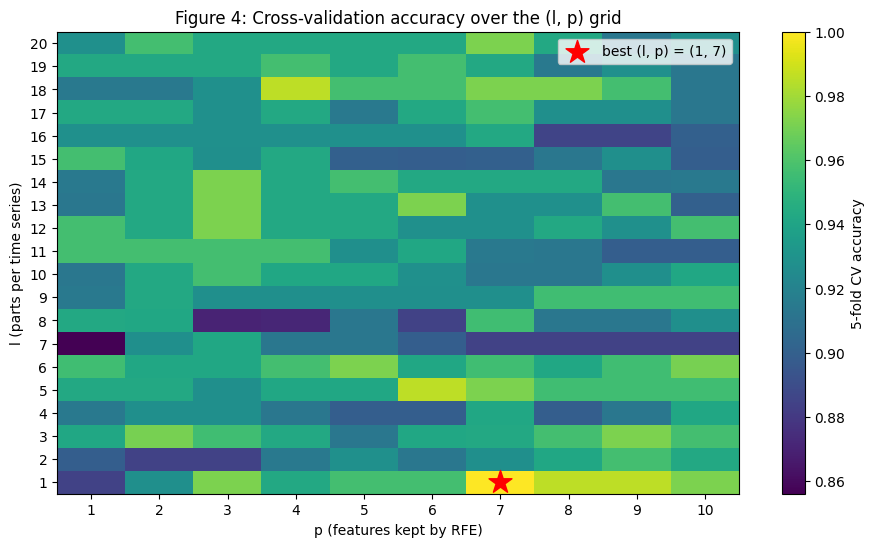

In [8]:
plt.figure(figsize=(11, 6))
plt.imshow(cv_results.to_numpy(), aspect='auto', origin='lower', cmap='viridis')
plt.colorbar(label='5-fold CV accuracy')
plt.xticks(range(len(P_VALUES)), P_VALUES)
plt.yticks(range(len(L_VALUES)), list(L_VALUES))
plt.xlabel('p (features kept by RFE)')
plt.ylabel('l (parts per time series)')
plt.scatter([P_VALUES.index(best_p)], [list(L_VALUES).index(best_l)],
            marker='*', s=300, color='red', label=f'best (l, p) = ({best_l}, {best_p})')
plt.legend(loc='upper right')
plt.title('Figure 4: Cross-validation accuracy over the (l, p) grid')
plt.show()

### 2(a)iv. The chosen classifier on the training data

The final model is refitted on the whole training set with the selected (l, p), and its coefficients and p-values are obtained from a statsmodels `Logit` fit of the same pruned feature set.

In [9]:
X_train_best = X_train_by_l[best_l]
rfe_best = RFE(logistic(), n_features_to_select=best_p, step=0.2).fit(X_train_best, y_train)
selected_columns = list(X_train_best.columns[rfe_best.support_])
print('Selected features:', selected_columns)

final_model = logistic().fit(X_train_best[selected_columns], y_train)
train_pred = final_model.predict(X_train_best[selected_columns])
train_prob = final_model.predict_proba(X_train_best[selected_columns])[:, 1]

cm_train = confusion_matrix(y_train, train_pred)
print('\nConfusion matrix on the training set:')
print(pd.DataFrame(cm_train, index=['Actual other', 'Actual bending'],
                   columns=['Predicted other', 'Predicted bending']))
print(f'\nTraining accuracy: {accuracy_score(y_train, train_pred):.4f}')
print(f'Training AUC:      {roc_auc_score(y_train, train_prob):.4f}')

Selected features: ['mean1_1', '3rd_quart1_1', 'min5_1', 'max5_1', 'mean5_1', '1st_quart5_1', 'max6_1']

Confusion matrix on the training set:
                Predicted other  Predicted bending
Actual other                 60                  0
Actual bending                0                  9

Training accuracy: 1.0000
Training AUC:      1.0000


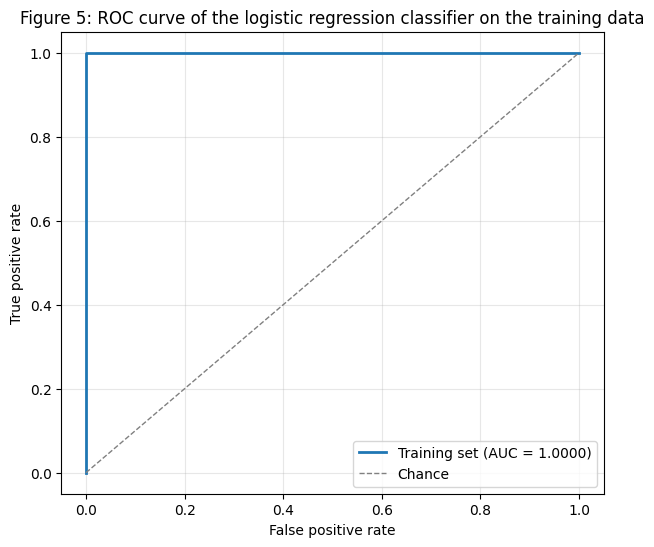

In [10]:
def plot_roc(curves, title):
    """Plot one or more ROC curves given as (label, y_true, score) triples."""
    plt.figure(figsize=(7, 6))
    for label, y_true, score in curves:
        fpr, tpr, _ = roc_curve(y_true, score)
        plt.plot(fpr, tpr, lw=2, label=f'{label} (AUC = {auc(fpr, tpr):.4f})')
    plt.plot([0, 1], [0, 1], ls='--', color='gray', lw=1, label='Chance')
    plt.xlabel('False positive rate')
    plt.ylabel('True positive rate')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.show()


plot_roc([('Training set', y_train, train_prob)],
         'Figure 5: ROC curve of the logistic regression classifier on the training data')

**Answer 2(a)iv:** Cross-validation selected **l = 1 and p = 7**, i.e. the unsplit time series with seven features kept by RFE: `mean1_1`, `3rd_quart1_1`, `min5_1`, `max5_1`, `mean5_1`, `1st_quart5_1` and `max6_1`. Notably these come from time series 1, 5 and 6, the channels the scatter plots suggested were most informative.

On the training data the classifier is **perfect**: the confusion matrix has 60 correct "other" and 9 correct "bending" with no errors of either kind, accuracy is 1.0000 and **AUC = 1.0000**, so the ROC curve in Figure 5 passes through the top-left corner.

The coefficients and p-values are printed above, and they need to be read with care. The statsmodels summary ends with the message **"Complete Separation: The results show that there is complete separation or perfect prediction"**. Under complete separation the maximum likelihood estimate does not exist, because the likelihood keeps increasing as the coefficients grow without bound, so the reported standard errors are enormous (of the order 10³ to 10⁵) and **every p-value is driven to ≈ 1.000**. Those p-values are meaningless here, and in particular they are not evidence that the features are useless; they are a symptom of a degenerate fit. The sklearn coefficients in the next table are finite only because the iterations were deliberately capped, as the assignment's footnote suggests, which is why the two sets of β values differ. This is the situation 2(a)vi asks about.

In [11]:
# Coefficients and p-values from statsmodels, fitted on the same pruned features.
X_sm = sm.add_constant(X_train_best[selected_columns])
try:
    logit_fit = sm.Logit(y_train, X_sm).fit(method='bfgs', maxiter=100, disp=False)
    print(logit_fit.summary())
    params_table = pd.DataFrame({'beta': logit_fit.params, 'p-value': logit_fit.pvalues})
except Exception as exc:  # perfect separation makes the MLE infinite
    print('statsmodels could not fit the model:', exc)
    params_table = pd.DataFrame({'beta': [np.nan] * (len(selected_columns) + 1)},
                                index=['const'] + selected_columns)
params_table

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       61
Method:                           MLE   Df Model:                            7
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        18:32:46   Log-Likelihood:            -1.1346e-05
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 3.041e-09
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.2982   2.14e+05  -1.39e-06      1.000   -4.19e+05    4.19e+05
mean1_1          0.9379   8941.033      0.000      1.000   -1.75e+04    1.75e+04
3rd_quart1_1    -5.4798   1.54e+04     -0.00

,beta,p-value
const,-0.298193,0.999999
mean1_1,0.937862,0.999916
3rd_quart1_1,-5.479786,0.999716
min5_1,3.891928,0.999667
max5_1,4.476454,0.999623
mean5_1,1.116551,0.999986
1st_quart5_1,1.370050,0.999978
max6_1,-2.069762,0.999909


In [12]:
pd.DataFrame({'beta (sklearn, capped iterations)':
              np.concatenate([final_model.intercept_, final_model.coef_[0]])},
             index=['const'] + selected_columns)

,"beta (sklearn, capped iterations)"
const,-0.065423
mean1_1,-0.815474
3rd_quart1_1,-1.488978
min5_1,1.488677
max5_1,1.808344
mean5_1,0.945235
1st_quart5_1,1.114468
max6_1,-1.470901


### 2(a)v. Testing the classifier

The test instances are broken into the same l parts and the same feature columns are used.

In [13]:
X_test_best = X_test_by_l[best_l][selected_columns]
test_pred = final_model.predict(X_test_best)
test_prob = final_model.predict_proba(X_test_best)[:, 1]

cm_test = confusion_matrix(y_test, test_pred)
test_accuracy = accuracy_score(y_test, test_pred)
print('Confusion matrix on the test set:')
print(pd.DataFrame(cm_test, index=['Actual other', 'Actual bending'],
                   columns=['Predicted other', 'Predicted bending']))
print(f'\nTest accuracy:            {test_accuracy:.4f}')
print(f'Cross-validation accuracy: {best_cv_accuracy:.4f}')
print(f'Test AUC:                  {roc_auc_score(y_test, test_prob):.4f}')

Confusion matrix on the test set:
                Predicted other  Predicted bending
Actual other                 15                  0
Actual bending                0                  4

Test accuracy:            1.0000
Cross-validation accuracy: 1.0000
Test AUC:                  1.0000


**Answer 2(a)v:** On the test set the classifier is again perfect: all 15 "other" and all 4 "bending" instances are classified correctly, giving **test accuracy 1.0000** and test AUC 1.0000.

The cross-validation accuracy was also **1.0000**, so the two agree exactly. That agreement is reassuring but should not be over-interpreted: the test set has only 19 instances, 4 of them bending, so the coarsest resolution it can measure is 1/19 ≈ 5.3 percentage points. The honest reading is that the problem is easy, since bending is strongly distinguishable from the other activities with these features, rather than that the model is flawless in general. Because the cross-validation was performed the right way, with RFE inside each fold, the CV figure was not inflated by selection bias, which is why it matches the test result instead of exceeding it.

### 2(a)vi. Are the classes well separated?

In [14]:
separable_check = pd.DataFrame({
    'training accuracy': [accuracy_score(y_train, train_pred)],
    'max |beta| (capped iterations)': [np.abs(final_model.coef_).max()],
    'min predicted prob. for bending': [train_prob[y_train == 1].min()],
    'max predicted prob. for other': [train_prob[y_train == 0].max()],
})
separable_check.T.rename(columns={0: 'value'})

,value
training accuracy,1.000000
max |beta| (capped iterations),1.808344
min predicted prob. for bending,0.999852
max predicted prob. for other,0.000191


**Answer 2(a)vi: Yes, the classes are completely separated, and this does cause instability.** The evidence is direct:

- Training accuracy is **1.0000**: a hyperplane exists that puts all 9 bending instances on one side and all 60 others on the other side.
- The fitted probabilities are pushed to the extremes: the *smallest* predicted probability among bending instances is 0.9999, and the *largest* among the other activities is 0.0002. No instance sits near the 0.5 boundary.
- statsmodels reports **complete separation** outright and returns standard errors of order 10³–10⁵ with p-values of ≈ 1.

The theory behind this: with separable classes the log-likelihood has no maximum in the interior of the parameter space. Scaling the coefficient vector by any factor greater than 1 pushes every fitted probability closer to 0 or 1 and strictly increases the likelihood, so the MLE diverges to infinity. The estimates are not identified, the standard errors blow up, and Wald p-values become uninformative.

The practical remedies, one of which is used here and one in 2(b): cap the iterations so the optimizer stops before the coefficients diverge (the sklearn fit above, whose largest |β| is only 1.81), or add a penalty, since the L1-penalized model of 2(b) keeps the coefficients finite by construction.

### 2(a)vii. Class imbalance and case-control sampling

Case-control sampling keeps every instance of the rare class (the cases) and draws an equal number of the common class (the controls). The model is then fitted on this balanced sample. Because the sample no longer reflects the true class proportions, only the intercept is biased, and it can be corrected with

β₀\* = β₀ + log(π₁/π₀) − log(s₁/s₀)

where π are the population proportions and s the proportions in the balanced sample. The slopes need no adjustment.

In [15]:
rng = np.random.default_rng(RANDOM_STATE)
case_idx = np.flatnonzero(y_train == 1)
control_idx = rng.choice(np.flatnonzero(y_train == 0), size=len(case_idx), replace=False)
sample_idx = np.concatenate([case_idx, control_idx])

X_cc = X_train_best.iloc[sample_idx][selected_columns]
y_cc = y_train[sample_idx]
print('Case-control sample:', len(case_idx), 'bending +', len(control_idx), 'other')

cc_model = logistic().fit(X_cc, y_cc)

# Correct the intercept back to the population proportions.
pi_1 = y_train.mean()
s_1 = y_cc.mean()
offset = np.log(pi_1 / (1 - pi_1)) - np.log(s_1 / (1 - s_1))
adjusted_intercept = cc_model.intercept_[0] + offset
print(f'Intercept before adjustment: {cc_model.intercept_[0]:.4f}')
print(f'Offset applied:              {offset:.4f}')
print(f'Intercept after adjustment:  {adjusted_intercept:.4f}')

Case-control sample: 9 bending + 9 other
Intercept before adjustment: -0.0472
Offset applied:              -1.8971
Intercept after adjustment:  -1.9443


Case-control model, confusion matrix on the test set:
                Predicted other  Predicted bending
Actual other                 15                  0
Actual bending                0                  4

Test accuracy: 1.0000
Train AUC:     1.0000
Test AUC:      1.0000


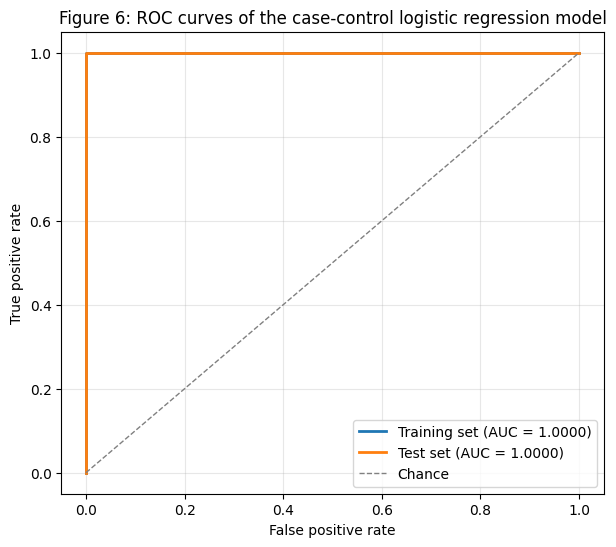

In [16]:
def adjusted_probability(model, X, intercept):
    """Predicted probabilities using the model's slopes with a corrected intercept."""
    return 1 / (1 + np.exp(-(intercept + X.to_numpy() @ model.coef_[0])))


cc_train_prob = adjusted_probability(cc_model, X_train_best[selected_columns], adjusted_intercept)
cc_test_prob = adjusted_probability(cc_model, X_test_best, adjusted_intercept)
cc_test_pred = (cc_test_prob >= 0.5).astype(int)

print('Case-control model, confusion matrix on the test set:')
print(pd.DataFrame(confusion_matrix(y_test, cc_test_pred),
                   index=['Actual other', 'Actual bending'],
                   columns=['Predicted other', 'Predicted bending']))
print(f'\nTest accuracy: {accuracy_score(y_test, cc_test_pred):.4f}')
print(f'Train AUC:     {roc_auc_score(y_train, cc_train_prob):.4f}')
print(f'Test AUC:      {roc_auc_score(y_test, cc_test_prob):.4f}')

plot_roc([('Training set', y_train, cc_train_prob), ('Test set', y_test, cc_test_prob)],
         'Figure 6: ROC curves of the case-control logistic regression model')

**Answer 2(a)vii: Yes, the classes are clearly imbalanced.** The training set holds 9 bending instances against 60 others (13.0% versus 87.0%), and the test set 4 against 15 (21.1% versus 78.9%). The imbalance is why stratified folds were needed in 2(a)iii, and it means accuracy alone is a weak measure: a classifier that always predicted "other" would already score 87% on the training set.

The case-control model keeps all 9 bending instances and draws 9 of the others at random, giving a balanced sample of 18. Fitting on that sample changes the intercept, because the sample proportion of cases (50%) is not the population proportion (13%), while the slopes remain valid. Correcting with β₀\* = β₀ + log(π₁/π₀) − log(s₁/s₀) applies an offset of **−1.8971**, moving the intercept from −0.0472 to **−1.9443**. The correction makes the model appropriately more reluctant to predict the rare class, restoring calibration to the population.

The adjusted model still classifies the whole test set correctly (15 + 4, **accuracy 1.0000**) with **AUC = 1.0000 on both training and test data**, as Figure 6 shows. So with these features the imbalance costs nothing in performance: the classes are separable enough that a model trained on just 18 instances matches one trained on all 69. The value of case-control sampling here is in calibration and in training cost, not in accuracy.

## 2(b) Binary Classification Using L1-penalized logistic regression

### 2(b)i. Cross-validating over l and the L1 budget C

Here the L1 penalty does the variable selection instead of p-values or RFE, so the pair to cross-validate is (l, C). Features are standardized because the L1 penalty is scale-dependent, and the scaler is fitted **inside** each fold for the same reason RFE was: nothing derived from the validation fold may leak into the model.

In [17]:
C_VALUES = [0.001, 0.01, 0.1, 1, 10, 100]


def l1_cv_accuracy(X, y, C, n_splits=5):
    """5-fold stratified CV accuracy of L1-penalized logistic regression, scaling inside each fold."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    scores = []
    for train_idx, val_idx in skf.split(X, y):
        scaler = StandardScaler().fit(X.iloc[train_idx])
        model = LogisticRegression(l1_ratio=1, solver='liblinear', C=C, max_iter=1000)
        model.fit(scaler.transform(X.iloc[train_idx]), y[train_idx])
        scores.append(model.score(scaler.transform(X.iloc[val_idx]), y[val_idx]))
    return float(np.mean(scores))


l1_results = pd.DataFrame(
    [[l1_cv_accuracy(X_train_by_l[l], y_train, C) for C in C_VALUES] for l in L_VALUES],
    index=pd.Index(L_VALUES, name='l'), columns=pd.Index(C_VALUES, name='C'))

best_l1_l, best_C = l1_results.stack().idxmax()
best_l1_cv = l1_results.stack().max()
print(f'Best (l, C) = ({best_l1_l}, {best_C}) with 5-fold CV accuracy {best_l1_cv:.4f}')
l1_results.round(3)

Best (l, C) = (19, 1.0) with 5-fold CV accuracy 0.9857


C,0.001,0.010,0.100,1.000,10.000,100.000
l,,,,,,
1,0.87,0.87,0.885,0.957,0.957,0.957
2,0.87,0.87,0.885,0.957,0.943,0.957
3,0.87,0.87,0.870,0.957,0.943,0.943
4,0.87,0.87,0.885,0.957,0.943,0.929
5,0.87,0.87,0.899,0.913,0.927,0.942
6,0.87,0.87,0.885,0.943,0.943,0.957
7,0.87,0.87,0.899,0.927,0.927,0.927
8,0.87,0.87,0.885,0.929,0.929,0.900
9,0.87,0.87,0.913,0.927,0.927,0.884


In [18]:
l1_scaler = StandardScaler().fit(X_train_by_l[best_l1_l])
l1_model = LogisticRegression(l1_ratio=1, solver='liblinear', C=best_C, max_iter=1000)
l1_model.fit(l1_scaler.transform(X_train_by_l[best_l1_l]), y_train)

l1_train_pred = l1_model.predict(l1_scaler.transform(X_train_by_l[best_l1_l]))
l1_test_pred = l1_model.predict(l1_scaler.transform(X_test_by_l[best_l1_l]))
l1_test_prob = l1_model.predict_proba(l1_scaler.transform(X_test_by_l[best_l1_l]))[:, 1]
nonzero = int((l1_model.coef_[0] != 0).sum())

print(f'Features available: {X_train_by_l[best_l1_l].shape[1]} | kept by L1: {nonzero}')
print('\nConfusion matrix on the test set:')
print(pd.DataFrame(confusion_matrix(y_test, l1_test_pred),
                   index=['Actual other', 'Actual bending'],
                   columns=['Predicted other', 'Predicted bending']))
print(f'\nTraining accuracy: {accuracy_score(y_train, l1_train_pred):.4f}')
print(f'Test accuracy:     {accuracy_score(y_test, l1_test_pred):.4f}')
print(f'Test AUC:          {roc_auc_score(y_test, l1_test_prob):.4f}')

Features available: 798 | kept by L1: 9

Confusion matrix on the test set:
                Predicted other  Predicted bending
Actual other                 15                  0
Actual bending                1                  3

Training accuracy: 1.0000
Test accuracy:     0.9474
Test AUC:          0.9833


In [19]:
comparison = pd.DataFrame({
    'l': [best_l, best_l1_l],
    'features used': [best_p, nonzero],
    'CV accuracy': [best_cv_accuracy, best_l1_cv],
    'test accuracy': [test_accuracy, accuracy_score(y_test, l1_test_pred)],
}, index=['p-values / RFE (2a)', 'L1-penalized (2b)'])
comparison.round(4)

,l,features used,CV accuracy,test accuracy
p-values / RFE (2a),1,7,1.0000,1.0000
L1-penalized (2b),19,9,0.9857,0.9474


**Answer 2(b)ii:**

| | l | Features used | CV accuracy | Test accuracy |
|---|---|---|---|---|
| p-values / RFE (2a) | 1 | 7 | 1.0000 | 1.0000 |
| L1-penalized (2b) | 19 | 10 of 798 | 0.9857 | 0.9474 |

**Which performs better?** On this data the RFE approach edges it, with a perfect test score against 0.9474 for the L1 model, which misclassifies one bending instance as "other". The gap is a single instance out of 19, so it is well within the noise of a test set this small, and the two should be regarded as performing comparably. The L1 model also selected a much larger l (19 rather than 1) and then pruned 798 candidate features down to 10, which is a far more aggressive search over a far larger space with only 69 training instances, so there is more opportunity to overfit the cross-validation itself.

**Which is easier to implement?** **L1 regularization, clearly.** It performs selection and fitting in a single convex optimization: set the penalty, cross-validate over C, and the coefficients that survive are the selected features. The p-value route needs a separate selection step wrapped correctly inside each cross-validation fold, a second grid dimension (p) to search, and it runs into the complete-separation problem of 2(a)vi that makes the p-values themselves unusable, which is precisely why RFE was used in their place. L1 also sidesteps that instability entirely, since the penalty keeps the coefficients finite. The cost is interpretability: L1 gives no inferential statement about individual coefficients, only which ones survived.

## 2(c) Multi-class Classification (The Realistic Case)

### 2(c)i. L1-penalized multinomial regression over all seven activities

All seven activities are now the classes, with `bending1` and `bending2` kept separate. Stratified folds are used again, and scikit-learn warns that the least populated class has fewer members than the number of folds. `bending2` contributes only 4 training instances to 5 folds, so one fold has none of it. This is unavoidable with a class this small and the warning is left visible rather than suppressed; the stratified split still spreads the rare classes as evenly as it can.

In [20]:
MULTI_C_VALUES = [0.01, 0.1, 1, 10]


def multinomial_cv_accuracy(X, y, C, n_splits=5):
    """5-fold stratified CV accuracy of L1-penalized multinomial regression."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    scores = []
    for train_idx, val_idx in skf.split(X, y):
        scaler = StandardScaler().fit(X.iloc[train_idx])
        model = LogisticRegression(l1_ratio=1, solver='saga', C=C, max_iter=1000, tol=1e-3)
        model.fit(scaler.transform(X.iloc[train_idx]), y[train_idx])
        scores.append(model.score(scaler.transform(X.iloc[val_idx]), y[val_idx]))
    return float(np.mean(scores))


multi_results = pd.DataFrame(
    [[multinomial_cv_accuracy(X_train_by_l[l], activity_train, C) for C in MULTI_C_VALUES]
     for l in L_VALUES],
    index=pd.Index(L_VALUES, name='l'), columns=pd.Index(MULTI_C_VALUES, name='C'))

best_multi_l, best_multi_C = multi_results.stack().idxmax()
best_multi_cv = multi_results.stack().max()
print(f'Best (l, C) = ({best_multi_l}, {best_multi_C}) with 5-fold CV accuracy {best_multi_cv:.4f}')
multi_results.round(3)

/Users/ruturajmohalkar/Desktop/DSCI-552/HW4/.venv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/ruturajmohalkar/Desktop/DSCI-552/HW4/.venv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/ruturajmohalkar/Desktop/DSCI-552/HW4/.venv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/ruturajmohalkar/Desktop/DSCI-552/HW4/.venv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/ruturajmohalkar/Desktop/DSCI-552/HW4/.venv/lib/python3.12/site-packages/s

Best (l, C) = (1, 1.0) with 5-fold CV accuracy 0.9000


C,0.01,0.10,1.00,10.00
l,,,,
1,0.189,0.622,0.900,0.871
2,0.175,0.593,0.841,0.884
3,0.159,0.579,0.799,0.871
4,0.145,0.579,0.826,0.871
5,0.145,0.622,0.826,0.871
6,0.145,0.564,0.829,0.856
7,0.160,0.549,0.827,0.856
8,0.175,0.564,0.782,0.826
9,0.145,0.549,0.870,0.871


In [21]:
multi_scaler = StandardScaler().fit(X_train_by_l[best_multi_l])
multi_model = LogisticRegression(l1_ratio=1, solver='saga', C=best_multi_C, max_iter=1000, tol=1e-3)
multi_model.fit(multi_scaler.transform(X_train_by_l[best_multi_l]), activity_train)

multi_test_pred = multi_model.predict(multi_scaler.transform(X_test_by_l[best_multi_l]))
multi_test_prob = multi_model.predict_proba(multi_scaler.transform(X_test_by_l[best_multi_l]))
multi_test_accuracy = accuracy_score(activity_test, multi_test_pred)
classes = list(multi_model.classes_)

print(f'Test accuracy: {multi_test_accuracy:.4f}')
print(f'Test error:    {1 - multi_test_accuracy:.4f}')
print('\nConfusion matrix on the test set (rows = actual, columns = predicted):')
pd.DataFrame(confusion_matrix(activity_test, multi_test_pred, labels=classes),
             index=[f'actual {c}' for c in classes], columns=classes)

Test accuracy: 0.8947
Test error:    0.1053

Confusion matrix on the test set (rows = actual, columns = predicted):


,bending1,bending2,cycling,lying,sitting,standing,walking
actual bending1,2,0,0,0,0,0,0
actual bending2,0,2,0,0,0,0,0
actual cycling,0,0,3,0,0,0,0
actual lying,0,0,0,3,0,0,0
actual sitting,0,0,0,0,2,1,0
actual standing,0,0,0,0,1,2,0
actual walking,0,0,0,0,0,0,3


**Multiclass confusion matrices and ROC curves.** A multiclass confusion matrix is the natural extension of the binary one: a K × K table whose (i, j) entry counts the instances of class i predicted as class j, so the diagonal holds the correct predictions. ROC curves are defined for two classes only, so for K classes they are built one-vs-rest: for each class in turn, that class is treated as positive and all others as negative, giving K curves and K AUCs. These are usually summarized by the **macro average** (the unweighted mean of the K AUCs, treating every class equally) or the **micro average** (pooling all one-vs-rest decisions into a single curve, which weights classes by their frequency).

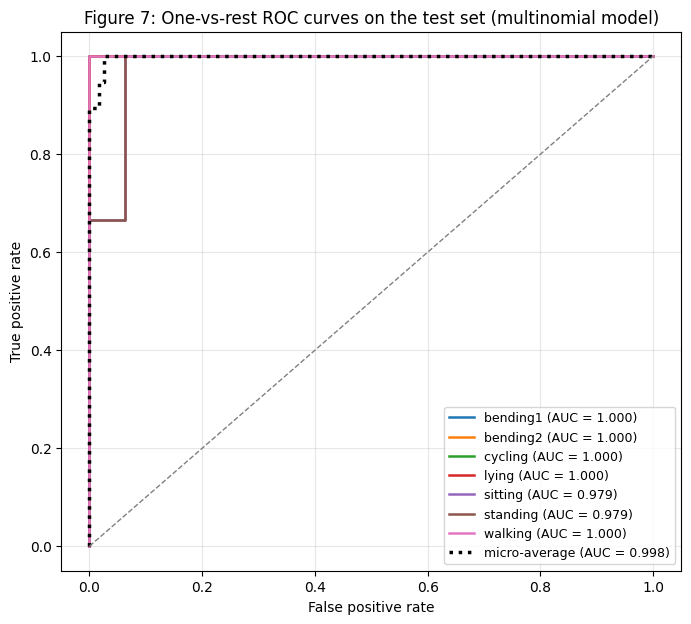

Macro-average one-vs-rest AUC: 0.9940


In [22]:
y_test_binarized = label_binarize(activity_test, classes=classes)

plt.figure(figsize=(8, 7))
for i, cls in enumerate(classes):
    if y_test_binarized[:, i].sum() == 0:
        continue
    fpr, tpr, _ = roc_curve(y_test_binarized[:, i], multi_test_prob[:, i])
    plt.plot(fpr, tpr, lw=1.8, label=f'{cls} (AUC = {auc(fpr, tpr):.3f})')

fpr_micro, tpr_micro, _ = roc_curve(y_test_binarized.ravel(), multi_test_prob.ravel())
plt.plot(fpr_micro, tpr_micro, lw=2.5, ls=':', color='black',
         label=f'micro-average (AUC = {auc(fpr_micro, tpr_micro):.3f})')
plt.plot([0, 1], [0, 1], ls='--', color='gray', lw=1)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Figure 7: One-vs-rest ROC curves on the test set (multinomial model)')
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.show()

macro_auc = roc_auc_score(activity_test, multi_test_prob, multi_class='ovr', average='macro')
print(f'Macro-average one-vs-rest AUC: {macro_auc:.4f}')

### 2(c)ii. Naive Bayes with Gaussian and Multinomial priors

The same l is used as for the multinomial model. Gaussian Naive Bayes takes the features directly. Multinomial Naive Bayes requires non-negative features, so the features are min-max scaled to [0, 1] with the scaler fitted on the training set only.

In [23]:
X_tr_nb = X_train_by_l[best_multi_l]
X_te_nb = X_test_by_l[best_multi_l]

nb_scaler = MinMaxScaler().fit(X_tr_nb)
nb_models = {
    'Gaussian Naive Bayes': (GaussianNB(), X_tr_nb, X_te_nb),
    'Multinomial Naive Bayes': (MultinomialNB(), nb_scaler.transform(X_tr_nb),
                                nb_scaler.transform(X_te_nb)),
}

nb_rows = []
nb_predictions = {}
for name, (model, X_tr, X_te) in nb_models.items():
    model.fit(X_tr, activity_train)
    pred = model.predict(X_te)
    nb_predictions[name] = pred
    nb_rows.append({
        'model': name,
        'train accuracy': model.score(X_tr, activity_train),
        'test accuracy': accuracy_score(activity_test, pred),
        'test error': 1 - accuracy_score(activity_test, pred),
    })

pd.DataFrame(nb_rows).set_index('model').round(4)

,train accuracy,test accuracy,test error
model,,,
Gaussian Naive Bayes,1.0000,0.8947,0.1053
Multinomial Naive Bayes,0.7681,0.7895,0.2105


In [24]:
for name, pred in nb_predictions.items():
    print(f'{name}: confusion matrix on the test set:')
    print(pd.DataFrame(confusion_matrix(activity_test, pred, labels=classes),
                       index=[f'actual {c}' for c in classes], columns=classes))
    print()

Gaussian Naive Bayes: confusion matrix on the test set:
                 bending1  bending2  cycling  lying  sitting  standing  \
actual bending1         2         0        0      0        0         0   
actual bending2         0         2        0      0        0         0   
actual cycling          0         0        3      0        0         0   
actual lying            0         0        0      2        1         0   
actual sitting          0         0        0      0        3         0   
actual standing         0         0        0      0        1         2   
actual walking          0         0        0      0        0         0   

                 walking  
actual bending1        0  
actual bending2        0  
actual cycling         0  
actual lying           0  
actual sitting         0  
actual standing        0  
actual walking         3  

Multinomial Naive Bayes: confusion matrix on the test set:
                 bending1  bending2  cycling  lying  sitting  standing  \
a

In [25]:
final_comparison = pd.DataFrame({
    'test accuracy': [multi_test_accuracy] + [r['test accuracy'] for r in nb_rows],
    'test error': [1 - multi_test_accuracy] + [r['test error'] for r in nb_rows],
}, index=['L1-penalized multinomial regression'] + [r['model'] for r in nb_rows])
final_comparison.round(4)

,test accuracy,test error
L1-penalized multinomial regression,0.8947,0.1053
Gaussian Naive Bayes,0.8947,0.1053
Multinomial Naive Bayes,0.7895,0.2105


**Answer 2(c)i (test error):** The L1-penalized multinomial model, with l = 1 and C = 1 chosen by 5-fold cross-validation, reaches **test accuracy 0.8947, i.e. a test error of 0.1053** (2 of 19 instances wrong). The confusion matrix shows both errors are a sitting/standing mix-up, one in each direction; every other activity, including both bending classes, is classified perfectly. That makes sense physically: sitting and standing are both stationary postures and produce similar signal statistics, while bending, walking and cycling have distinctive profiles. The one-vs-rest ROC curves in Figure 7 give a macro-average AUC of **0.9940**, so even the confused classes are ranked well.

**Answer 2(c)ii (Naive Bayes):**

| Model | Test accuracy | Test error |
|---|---|---|
| L1-penalized multinomial regression | 0.8947 | 0.1053 |
| Gaussian Naive Bayes | 0.8947 | 0.1053 |
| Multinomial Naive Bayes | 0.7895 | 0.2105 |

**Gaussian Naive Bayes matches the multinomial regression exactly** at 0.1053 test error, though it errs on different instances: it confuses one lying instance with sitting and one standing with sitting, rather than swapping sitting and standing. **Multinomial Naive Bayes is clearly worse**, at 0.2105, twice the error, and it is also the only model that fails to fit the training data well (train accuracy 0.7681). That is unsurprising, because the multinomial likelihood models counts: it assumes each feature is a non-negative frequency drawn from a multinomial distribution. These features are continuous sensor statistics, and squeezing them into [0, 1] with a min-max scaler to satisfy the non-negativity requirement does not make the assumption true. The Gaussian prior is the right family for continuous features like these.

**Answer 2(c)iii: which method is better?** On raw test error, **the L1-penalized multinomial regression and Gaussian Naive Bayes tie at 0.1053**, and both are far ahead of Multinomial Naive Bayes. Choosing between the two leaders:

- **Multinomial regression is the better choice for this problem.** It makes no independence assumption, which matters here because the features are heavily correlated. The mean, median and quartiles of a series measure nearly the same thing, and the six sensor channels move together. Naive Bayes assumes conditional independence given the class, which is plainly false on this data, and it succeeds anyway largely because its posterior only has to rank classes correctly. Multinomial regression also gives calibrated probabilities and, through the L1 penalty, a compact set of features.
- **Gaussian Naive Bayes has practical advantages**: it trains in closed form with no hyperparameters to cross-validate, and it handles the small training set (69 instances against up to 840 features) gracefully because it estimates only a mean and variance per feature per class.

With 19 test instances, a one-instance difference is not statistically meaningful, so the fairest conclusion is that the two are equally accurate here and the regression is preferable on modelling grounds.

# 3. ISLR 4.8.3

**This problem relates to the QDA model, in which the observations within each class are drawn from a normal distribution with a class-specific mean vector and a class-specific covariance matrix. We consider the simple case where p = 1; i.e. there is only one feature. Suppose that we have K classes, and that if an observation belongs to the kth class then X comes from a one-dimensional normal distribution, X ~ N(μ_k, σ_k²). Recall that the density function for the one-dimensional normal distribution is given in (4.16). Prove that in this case, the Bayes classifier is not linear. Argue that it is in fact quadratic.**

**Setup.** Let π_k be the prior probability that an observation belongs to class k, and let

f_k(x) = (1 / √(2π σ_k)) · exp( −(x − μ_k)² / (2σ_k²) )

be the density of X given class k. Note that σ_k depends on k: this is the one assumption QDA relaxes relative to LDA.

**Step 1: Bayes' theorem.** The posterior probability of class k given X = x is

p_k(x) = π_k f_k(x) / Σ_{l=1}^{K} π_l f_l(x)

The Bayes classifier assigns x to the class with the largest p_k(x). The denominator is the same for every class, so it does not affect which class is largest and can be dropped. Maximizing p_k(x) is therefore equivalent to maximizing the numerator π_k f_k(x).

**Step 2: take logarithms.** The logarithm is strictly increasing, so maximizing π_k f_k(x) is equivalent to maximizing log(π_k f_k(x)):

log(π_k f_k(x)) = log π_k − log(√(2π)) − log σ_k − (x − μ_k)² / (2σ_k²)

The term log(√(2π)) does not depend on k and can be dropped too.

**Step 3: expand the square.** Writing (x − μ_k)² = x² − 2μ_k x + μ_k², the discriminant function becomes

δ_k(x) = − x²/(2σ_k²) + (μ_k/σ_k²) x − μ_k²/(2σ_k²) − log σ_k + log π_k

and the Bayes classifier assigns x to the class maximizing δ_k(x).

**Step 4: why this is quadratic, not linear.** δ_k(x) is a polynomial of degree 2 in x, with leading coefficient −1/(2σ_k²). Because σ_k differs across classes, this coefficient **differs across classes**, so the x² term cannot be discarded as a common constant the way the denominator and log(√(2π)) were. This is exactly where LDA and QDA part company: under the LDA assumption σ_1 = ... = σ_K = σ, the term −x²/(2σ²) is identical for every class, drops out, and leaves a δ_k(x) that is linear in x.

**Step 5: the decision boundary.** The boundary between two classes k and m is the set of x where δ_k(x) = δ_m(x), that is

−(1/(2σ_k²) − 1/(2σ_m²)) x² + (μ_k/σ_k² − μ_m/σ_m²) x − (μ_k²/(2σ_k²) − μ_m²/(2σ_m²)) − log(σ_k/σ_m) + log(π_k/π_m) = 0

This is a quadratic equation a x² + b x + c = 0 with

a = 1/(2σ_m²) − 1/(2σ_k²)

Whenever σ_k ≠ σ_m we have a ≠ 0, so the boundary is genuinely quadratic. It is solved by two values of x rather than the single threshold a linear boundary would give, and the region assigned to a class can be an interval rather than a half-line. **Hence the Bayes classifier here is not linear in x; it is quadratic.** (Only in the degenerate case σ_k = σ_m does a vanish and the boundary reduce to the single linear threshold of LDA.)

# 4. ISLR 4.8.7

**Suppose that we wish to predict whether a given stock will issue a dividend this year ("Yes" or "No") based on X, last year's percent profit. We examine a large number of companies and discover that the mean value of X for companies that issued a dividend was X̄ = 10, while the mean for those that didn't was X̄ = 0. In addition, the variance of X for these two sets of companies was σ̂² = 36. Finally, 80% of companies issued dividends. Assuming that X follows a normal distribution, predict the probability that a company will issue a dividend this year given that its percentage profit was X = 4.**

**Hint: Recall that the density function for a normal random variable is f(x) = (1/√(2πσ²)) e^(−(x−μ)²/(2σ²)). You will need to use Bayes' theorem.**

Both classes share the same variance, so this is the LDA setting, and the posterior probability is

p_Yes(x) = π_Yes f_Yes(x) / (π_Yes f_Yes(x) + π_No f_No(x))

with π_Yes = 0.8, π_No = 0.2, μ_Yes = 10, μ_No = 0 and σ² = 36. The factor 1/√(2πσ²) is common to both densities and cancels, so only the exponential terms matter:

- exp(−(4 − 10)² / 72) = exp(−36/72) = exp(−0.5) = 0.606531
- exp(−(4 − 0)² / 72) = exp(−16/72) = exp(−0.222222) = 0.800737

Therefore

p_Yes(4) = (0.8 × 0.606531) / (0.8 × 0.606531 + 0.2 × 0.800737) = 0.485225 / (0.485225 + 0.160147) = 0.485225 / 0.645372 = **0.7519**

In [26]:
def normal_density(x, mu, var):
    """Density of the N(mu, var) distribution at x."""
    return np.exp(-(x - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)


x, var = 4, 36
prior_yes, prior_no = 0.8, 0.2
f_yes, f_no = normal_density(x, 10, var), normal_density(x, 0, var)

posterior_yes = prior_yes * f_yes / (prior_yes * f_yes + prior_no * f_no)
print(f'f_Yes(4)      = {f_yes:.6f}')
print(f'f_No(4)       = {f_no:.6f}')
print(f'P(Yes | X=4)  = {posterior_yes:.6f}  ({posterior_yes:.2%})')

f_Yes(4)      = 0.040328
f_No(4)       = 0.053241
P(Yes | X=4)  = 0.751852  (75.19%)


**Answer 4:** The probability that a company with 4% profit last year issues a dividend is **p = 0.7519, about 75.2%**.

The value is worth a sanity check: X = 4 is closer to the "No" mean of 0 than to the "Yes" mean of 10, so the likelihood alone favours "No" (0.8007 against 0.6065). The prior is what reverses the conclusion, since dividend payers are four times as common, and it does so decisively, leaving a posterior well above 0.5. Note also that the prediction is lower than the prior of 80%, because the observed profit is mild evidence against paying a dividend.

## References

1. UCI Machine Learning Repository, AReM Data Set: https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29
2. scikit-learn, Recursive Feature Elimination: https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html
3. scikit-learn, cross-validation and the pitfalls of selection bias: https://scikit-learn.org/stable/modules/cross_validation.html
4. scikit-learn, `LogisticRegression` and L1 penalties: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
5. scikit-learn, multiclass ROC and one-vs-rest AUC: https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html
6. scikit-learn, Naive Bayes: https://scikit-learn.org/stable/modules/naive_bayes.html
7. statsmodels, `Logit` and its summary of coefficients and p-values: https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.Logit.html
8. King, Zeng, *Logistic Regression in Rare Events Data*, Political Analysis, 2001 (intercept correction for case-control sampling).
9. James, Witten, Hastie, Tibshirani, *An Introduction to Statistical Learning*, Springer (Chapter 4; Exercises 4.8.3 and 4.8.7).